In [44]:
#F0484 Melbourne Housing Market - Price
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from data_analysis import summarize_categorical, summarize_numeric
from graphviz import Digraph
import os

pd.set_option('display.width', 1000)
pd.set_option('display.max_columns', None)

filename = '../MELBOURNE_HOUSE_PRICES_LESS.csv'
df = pd.read_csv(filename)
categorical_col = df.select_dtypes(include=['object']).columns.tolist()
numeric_col = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

Dataset

In [45]:
#split into train, validation and test ds
rng = np.random.RandomState(42)
perm = rng.permutation(len(df)) #shuffle indices

train_split_index = int(0.8 * len(df))
validation_split_index = int(0.9 * len(df))

train_df = df.iloc[perm[:train_split_index]].copy() #select all of the indices up to split_ind and map them to real rows
validation_df = df.iloc[perm[train_split_index:validation_split_index]].copy()
test_df = df.iloc[perm[validation_split_index:]].copy()
print(f"Train:\n {train_df.head(5)}\nValidation:\n{validation_df.head(5)}\nTest: \n{test_df.head(5)}")

Train:
                Suburb             Address  Rooms Type      Price Method     SellerG        Date  Postcode             Regionname  Propertycount  Distance                 CouncilArea
11013      Aberfeldie    8/257 Buckley St      2    u   470000.0      S        Brad   7/05/2016      3040   Western Metropolitan           1543       7.5  Moonee Valley City Council
34702        Armadale  5/92 Wattletree Rd      2    u        NaN     SN     Thomson  18/03/2017      3143  Southern Metropolitan           4836       6.3    Stonnington City Council
52485  Altona Meadows          17 Hall Av      3    u   530000.0     SP      Barlow  26/05/2018      3028   Western Metropolitan           7630      15.5    Hobsons Bay City Council
32079      Camberwell       29 Dominic St      4    h  2650000.0     PI          RT  17/02/2018      3124  Southern Metropolitan           8920       7.7     Boroondara City Council
7696        Yallambie          6 Ovata Cl      3    h   815000.0      S  Buckingha

In [46]:
num_test_sum = summarize_numeric(test_df[numeric_col])
cat_test_sum = summarize_categorical(test_df[categorical_col])
num_validation_sum = summarize_numeric(validation_df[numeric_col])
cat_validation_sum = summarize_categorical(validation_df[categorical_col])

In [47]:
print(f"Numerical test df: \n{num_test_sum}\n")
print(f"Categorical test df: \n{cat_test_sum}\n")

print(f"Numerical validation df: \n{num_validation_sum}\n")
print(f"Categorical validation df: \n{cat_validation_sum}\n")

Numerical test df: 
          column     N  % missing  cardinality       min        Q1    median         Q3        max           mean            std
0          Rooms  6303       0.00            8       1.0       3.0       3.0        4.0        8.0       3.102967       0.926887
1          Price  6303      22.97         1283  200000.0  617750.0  820000.0  1205000.0  9000000.0  990031.699279  585020.067152
2       Postcode  6303       0.00          194    3000.0    3055.0    3106.0     3165.0     3977.0    3125.511978     127.143159
3  Propertycount  6303       0.00          310     342.0    4380.0    6543.0    10331.0    21650.0    7492.140727    4320.090709
4       Distance  6303       0.00          155       0.0       7.0      11.7       17.2       48.1      12.765112       7.581948

Categorical test df: 
        column     N  % missing  cardinality                     mode  mode freq  mode %                 mode 2  mode 2 freq  mode 2 %
0       Suburb  6303        0.0          315    

In [48]:
#1. duplicate rows
print("Duplicate rows in training df:", train_df.duplicated().sum())
print("Duplicate rows in validation df:", validation_df.duplicated().sum())
train_df = train_df.drop_duplicates()
validation_df = validation_df.drop_duplicates()

Duplicate rows in training df: 1
Duplicate rows in validation df: 0


In [49]:
#2. missing target values
print(f"train_df count before: {len(train_df)}")
train_df = train_df.dropna(subset=['Price'])
print(f"train_df count after: {len(train_df)}")

print(f"validation_df count before: {len(validation_df)}")
validation_df = validation_df.dropna(subset=['Price'])
print(f"validation_df count after: {len(validation_df)}")

train_df count before: 50417
train_df count after: 38707
validation_df count before: 6302
validation_df count after: 4870


In [50]:
#3. Outliers
Q1 = train_df['Price'].quantile(0.25)
Q3 = train_df['Price'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outliers = train_df[(train_df['Price'] < lower) | (train_df['Price'] > upper)]
print("Lower bound:", lower)
print("Upper bound:", upper)
print("Number of outliers:", len(outliers))

Lower bound: -280000.0
Upper bound: 2120000.0
Number of outliers: 1845


In [51]:
#4. Invalid values
print("Train df")
print("Price <= 50000:", (train_df['Price'] <= 0).sum())
print("Rooms <= 0:", (train_df['Rooms'] <= 0).sum())
print("Distance < 0:", (train_df['Distance'] < 0).sum())
print("Propertycount < 0:", (train_df['Propertycount'] < 0).sum())

print("\nValidation df")
print("Price <= 50000:", (validation_df['Price'] <= 0).sum())
print("Rooms <= 0:", (validation_df['Rooms'] <= 0).sum())
print("Distance < 0:", (validation_df['Distance'] < 0).sum())
print("Propertycount < 0:", (validation_df['Propertycount'] < 0).sum())

Train df
Price <= 50000: 0
Rooms <= 0: 0
Distance < 0: 0
Propertycount < 0: 0

Validation df
Price <= 50000: 0
Rooms <= 0: 0
Distance < 0: 0
Propertycount < 0: 0


In [52]:
#5. High cardinality 
print("Test df")
avg_price_council = (train_df.groupby('Regionname')['Price'].mean().sort_values(ascending=False))
counter = 0
for council, price in avg_price_council.items():
    counter += 1
    print(f"{council} : ${price:,.2f}")
    if counter == 8: break

print("\nValidation df")
avg_price_council = (validation_df.groupby('CouncilArea')['Price'].mean().sort_values(ascending=False))
counter = 0
for council, price in avg_price_council.items():
    counter += 1
    print(f"{council} : ${price:,.2f}")
    if counter == 8: break

top_councils = ['Boroondara City Council', 'Stonnington City Council', 'Bayside City Council']
train_df['CouncilArea'] = np.where(train_df['CouncilArea'].isin(top_councils), train_df['CouncilArea'], 'Other')
validation_df['CouncilArea'] = np.where(validation_df['CouncilArea'].isin(top_councils), validation_df['CouncilArea'], 'Other')

train_df['Regionname'] = np.where(train_df['Regionname'].isin(['Southern Metropolitan', 'Eastern Metropolitan']), train_df['Regionname'], 'Other')
validation_df['Regionname'] = np.where(validation_df['Regionname'].isin(['Southern Metropolitan', 'Eastern Metropolitan']), validation_df['Regionname'], 'Other')

Test df
Southern Metropolitan : $1,372,808.47
Eastern Metropolitan : $1,075,240.82
South-Eastern Metropolitan : $845,583.29
Northern Metropolitan : $826,088.25
Western Metropolitan : $800,165.08
Eastern Victoria : $686,804.00
Northern Victoria : $643,716.13
Western Victoria : $417,968.33

Validation df
Boroondara City Council : $1,689,938.57
Stonnington City Council : $1,553,885.83
Bayside City Council : $1,383,533.32
Manningham City Council : $1,206,064.78
Glen Eira City Council : $1,138,681.78
Monash City Council : $1,135,012.28
Yarra City Council : $1,097,916.43
Port Phillip City Council : $1,095,960.32


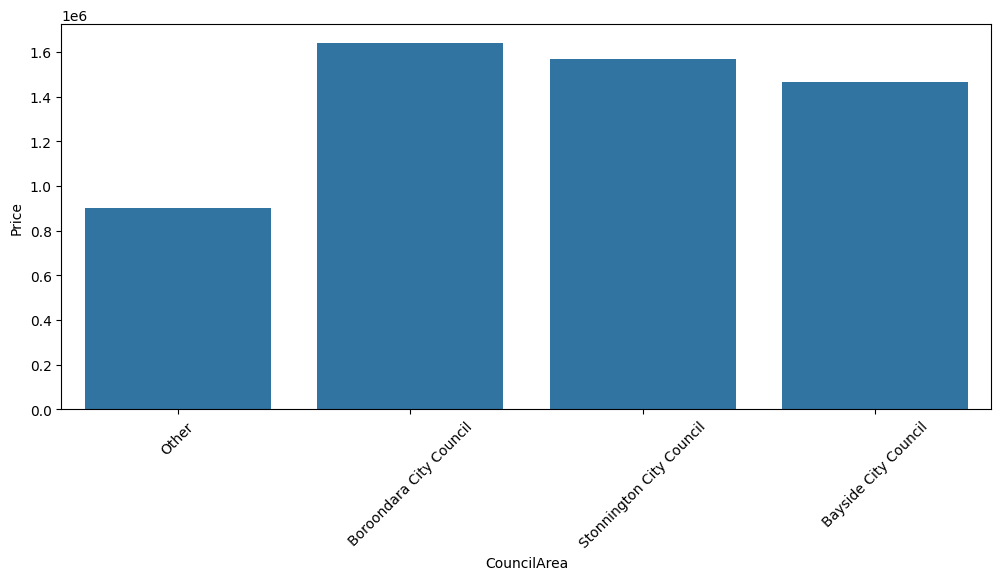

In [53]:
plt.figure(figsize=(12, 5))
sns.barplot(data=train_df, x='CouncilArea', y='Price', estimator='mean', errorbar=None)
plt.xticks(rotation=45)
plt.show()

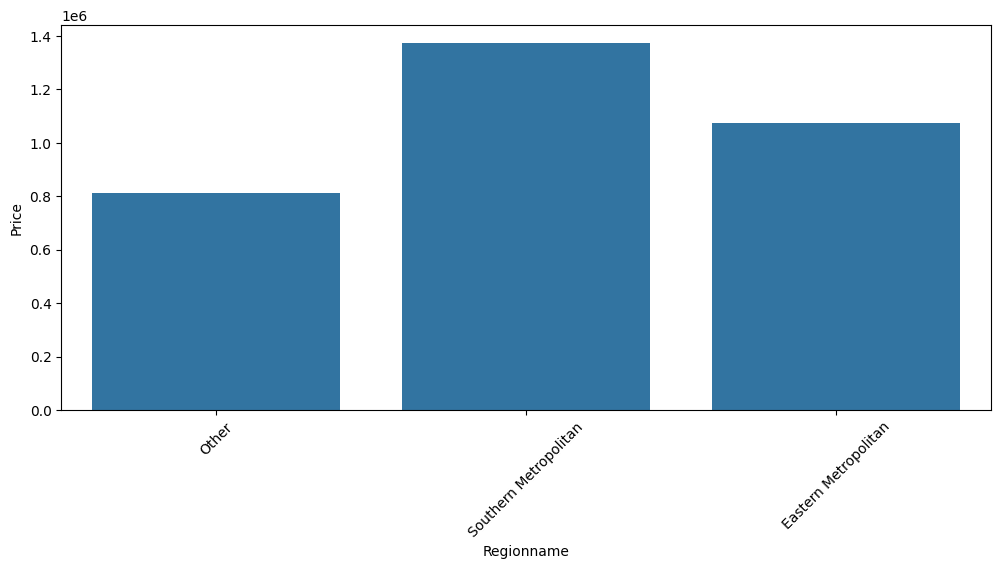

In [54]:
plt.figure(figsize=(12, 5))
sns.barplot(data=train_df, x='Regionname', y='Price', estimator='mean', errorbar=None)
plt.xticks(rotation=45)
plt.show()

In [55]:
categorical_cols = ['Type', 'Method', 'Regionname', 'CouncilArea']

In [56]:
#about councilarea i wouldn't drop them, just group according to top3 
train_df = train_df.drop(columns=['Address', 'Suburb', 'SellerG', 'Postcode'])
validation_df = validation_df.drop(columns=['Address', 'Suburb', 'SellerG', 'Postcode'])

In [57]:
train_df['Date'] = pd.to_datetime(train_df['Date'], dayfirst=True)
train_df['Age'] = 2026 - train_df['Date'].dt.year
validation_df['Date'] = pd.to_datetime(validation_df['Date'], dayfirst=True)
validation_df['Age'] = 2026 - validation_df['Date'].dt.year
train_df = train_df.drop(columns=["Date"])
validation_df = validation_df.drop(columns=["Date"])

In [58]:
print(validation_df.iloc[0])
print(train_df.iloc[0])

Rooms                   2
Type                    u
Price            340000.0
Method                 VB
Regionname          Other
Propertycount        7082
Distance              5.2
CouncilArea         Other
Age                     9
Name: 62339, dtype: object
Rooms                   2
Type                    u
Price            470000.0
Method                  S
Regionname          Other
Propertycount        1543
Distance              7.5
CouncilArea         Other
Age                    10
Name: 11013, dtype: object


In [59]:
train_df.head(10)

,Rooms,Type,Price,Method,Regionname,Propertycount,Distance,CouncilArea,Age
11013,2,u,470000.0,S,Other,1543,7.5,Other,10
52485,3,u,530000.0,SP,Other,7630,15.5,Other,8
32079,4,h,2650000.0,PI,Southern Metropolitan,8920,7.7,Boroondara City Council,8
7696,3,h,815000.0,S,Other,1369,12.7,Other,8
23186,6,h,1602000.0,S,Eastern Metropolitan,10999,14.3,Other,10
41332,4,h,1275000.0,S,Other,9264,7.5,Other,9
25732,4,h,775000.0,PI,Other,709,21.5,Other,8
13723,3,h,1150000.0,VB,Other,5087,21.5,Other,8
31493,4,h,814250.0,S,Other,17055,38.0,Other,9
17190,2,u,688500.0,S,Southern Metropolitan,2952,6.4,Other,9


Regression desicion tree

In [60]:
class Node:
    def __init__(self, feature=None, node_type=None, threshold=None, branches=None, value=None):
        self.feature = feature  #name of column to split on
        self.node_type = node_type  #'categorical', 'numeric', or 'leaf'
        self.threshold = threshold  #threshold float value fro numeric split
        self.branches = (branches if branches is not None else {})  #dict mapping branch key -> Node
        self.value = value  #leaf prediction value

    def is_leaf(self):
        return self.value is not None


class CustomRegressionTree:
    def __init__(self, max_depth=5, min_samples_split=5, num_thresholds=5, categorical_cols=None, binary_cols=None, numeric_cols=None):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.num_thresholds = max(5, num_thresholds)
        self.categorical_cols = categorical_cols or []
        self.binary_cols = binary_cols or []
        self.numeric_cols = numeric_cols or []
        self.root = None

    def _variance(self, y):
        if len(y) <= 1:
            return 0.0
        return np.sum((y - np.mean(y)) ** 2)

    def _evaluate_split(self, y_subsets): #calculate sum of squared errors
        total_sse = sum(self._variance(y_sub) for y_sub in y_subsets)
        return total_sse

    def _find_best_split(self, X, y): #goal - to minimize sse
        best_sse = float("inf")
        best_split = None
        parent_sse = self._variance(y)

        for col in X.columns:
            if col in self.categorical_cols: #if column is categorical feature
                categories = X[col].unique() #get all of values in column without repetition
                if len(categories) <= 1:
                    continue

                subsets_y = [y[X[col] == cat] for cat in categories] #split y into n separate groups (lists of y corresponding to each category: [[prices_cat1],[prices_cat2],[prices_cat3]])
                current_sse = self._evaluate_split(subsets_y)

                if current_sse < best_sse:
                    best_sse = current_sse
                    best_split = {
                        "feature": col,
                        "node_type": "categorical",
                        "categories": categories,
                        "threshold": None,
                    }

            elif col in self.binary_cols:
                vals = X[col].unique()
                if len(vals) <= 1:
                    continue

                val1 = vals[0]
                subsets_y = [y[X[col] == val1], y[X[col] != val1]]
                current_sse = self._evaluate_split(subsets_y)

                if current_sse < best_sse:
                    best_sse = current_sse
                    best_split = {
                        "feature": col,
                        "node_type": "binary",
                        "categories": [val1, "other"],
                        "threshold": None,
                    }

            #here we need to find feature, which ater splitting produces the lowest variance in target variable, 
            #because if we split data into 2 branches where each branch has least deviation between the values, model would perform good
            elif col in self.numeric_cols: #numerical feature
                unique_vals = np.sort(X[col].unique())
                if len(unique_vals) <= 1:
                    continue

                percentiles = np.linspace(10, 90, self.num_thresholds) #generate percentile markers
                thresholds = np.percentile(X[col].dropna(), percentiles) #convert percentiles into values
                thresholds = np.unique(thresholds) 

                for thresh in thresholds:
                    left_mask = X[col] <= thresh
                    right_mask = ~left_mask

                    if not np.any(left_mask) or not np.any(right_mask):
                        continue

                    subsets_y = [y[left_mask], y[right_mask]]
                    current_sse = self._evaluate_split(subsets_y)

                    if current_sse < best_sse:
                        best_sse = current_sse
                        best_split = {
                            "feature": col,
                            "node_type": "numeric",
                            "threshold": thresh,
                            "categories": None,
                        }

        #return best split only if it improves variance
        if best_sse < parent_sse:
            return best_split
        return None

    def _build_tree(self, X, y, depth=0):
        num_samples = len(y)

        #stopping cond
        if (depth >= self.max_depth or num_samples < self.min_samples_split or self._variance(y) == 0):
            return Node(value=np.mean(y) if num_samples > 0 else 0.0)

        split = self._find_best_split(X, y)
        if split is None:
            return Node(value=np.mean(y))

        node = Node(feature=split["feature"], node_type=split["node_type"], threshold=split["threshold"])
        col = split["feature"]

        if split["node_type"] == "categorical":
            for cat in split["categories"]:
                child_X = X[X[col] == cat]
                child_y = y[X[col] == cat]
                node.branches[cat] = self._build_tree(child_X, child_y, depth + 1)

        elif split["node_type"] == "binary":
            target_val = split["categories"][0]
            mask = X[col] == target_val

            node.branches[target_val] = self._build_tree(X[mask], y[mask], depth + 1)
            node.branches["other"] = self._build_tree(X[~mask], y[~mask], depth + 1)

        elif split["node_type"] == "numeric":
            thresh = split["threshold"]
            left_mask = X[col] <= thresh

            node.branches["<= threshold"] = self._build_tree(X[left_mask], y[left_mask], depth + 1)
            node.branches["> threshold"] = self._build_tree(X[~left_mask], y[~left_mask], depth + 1)
        return node

    def fit(self, X, y):
        X_df = X.copy().reset_index(drop=True)
        y_ser = y.copy().reset_index(drop=True)

        self.root = self._build_tree(X_df, y_ser, depth=0)
        return self

    def _predict_single(self, row, node):
        if node.is_leaf():
            return node.value

        val = row[node.feature]

        if node.node_type == "categorical":
            if val in node.branches:
                return self._predict_single(row, node.branches[val])
            else:
                leaf_vals = [self._get_leaf_mean(b) for b in node.branches.values()]
                return np.mean(leaf_vals)

        elif node.node_type == "binary":
            target_val = list(node.branches.keys())[0]
            if val == target_val:
                return self._predict_single(row, node.branches[target_val])
            else:
                return self._predict_single(row, node.branches["other"])

        elif node.node_type == "numeric":
            if val <= node.threshold:
                return self._predict_single(row, node.branches["<= threshold"])
            else:
                return self._predict_single(row, node.branches["> threshold"])

    def _get_leaf_mean(self, node):
        if node.is_leaf():
            return node.value
        return np.mean([self._get_leaf_mean(b) for b in node.branches.values()])

    def predict(self, X):
        X_df = X.copy().reset_index(drop=True)
        return np.array([self._predict_single(row, self.root) for _, row in X_df.iterrows()])
  
    def plot_my_tree(self, max_depth=3):
        import matplotlib.pyplot as plt

        if self.root is None:
            raise ValueError("The tree has not been fitted. Call fit() first.")

        fig, ax = plt.subplots(figsize=(24, 12))

        nodes = []
        edges = []

        # Collect every node in the tree
        def collect(node, parent=None, label="", depth=0):
            node_id = len(nodes)
            nodes.append((node, node_id))

            if parent is not None:
                edges.append((parent, node_id, label))

            if node.is_leaf() or depth >= max_depth:
                return

            for key, child in node.branches.items():
                if node.node_type == "numeric":
                    if key == "<= threshold":
                        condition = f"<= {node.threshold:.2f}"
                    else:
                        condition = f"> {node.threshold:.2f}"
                else:
                    condition = str(key)

                collect(child, node_id, condition, depth + 1)

        collect(self.root)

        # Calculate each node's depth and position
        positions = {}
        leaf_counter = [0]

        
        def position_tree(node, depth=0):
            node_id = next(
                node_id for n, node_id in nodes if n is node
            )

            # Treat nodes at max_depth as terminal for visualization
            if node.is_leaf() or depth >= max_depth:
                x = leaf_counter[0]
                leaf_counter[0] += 1
            else:
                child_positions = [
                    position_tree(child, depth + 1)
                    for child in node.branches.values()
                ]
                x = sum(child_positions) / len(child_positions)

            positions[node_id] = (x, -depth)
            return x


        position_tree(self.root)

        # Draw edges and split conditions
        for parent, child, label in edges:
            x1, y1 = positions[parent]
            x2, y2 = positions[child]

            ax.plot([x1, x2], [y1, y2], color="gray", linewidth=0.8)

            ax.text(
                (x1 + x2) / 2,
                (y1 + y2) / 2,
                label,
                fontsize=7,
                ha="center",
                va="center",
                bbox=dict(facecolor="white", alpha=0.8, edgecolor="none")
            )

        # Draw all nodes
        for node, node_id in nodes:
            x, y = positions[node_id]

            if node.is_leaf():
                text = f"Price = {node.value:,.0f}"
                color = "lightgreen"
            elif node.node_type == "numeric":
                text = f"{node.feature}\n<= {node.threshold:.2f}?"
                color = "lightblue"
            else:
                text = f"{node.feature}\n({node.node_type})"
                color = "lightblue"

            ax.text(
                x, y, text,
                ha="center",
                va="center",
                fontsize=8,
                bbox=dict(
                    boxstyle="round,pad=0.4",
                    facecolor=color,
                    edgecolor="black"
                )
            )

        # Adjust figure size for large trees
        max_depth = max(-y for x, y in positions.values())
        num_leaves = leaf_counter[0]

        fig.set_size_inches(
            max(16, num_leaves * 1.5),
            max(8, (max_depth + 1) * 1.5)
        )

        ax.set_xlim(-1, max(1, num_leaves))
        ax.set_ylim(-max_depth - 1, 1)
        ax.axis("off")
        ax.set_title("Full Custom Regression Tree")

        plt.tight_layout()
        plt.show()


In [61]:
def evaluate_metrics(y_true, y_pred):
    mse = np.mean((y_true - y_pred) ** 2)
    mae = np.mean(np.abs(y_true - y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    ss_res = np.sum((y_true - y_pred) ** 2)  #residual sum of squares
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)  #total sum of squares
    r2 = 1 - (ss_res / ss_tot)

    return {"MSE": mse, "MAE": mae, "MAPE (%)": mape, "R2": r2}

In [62]:
X_train = train_df.drop(columns='Price')
y_train = train_df["Price"]
X_validation = validation_df.drop(columns=['Price'])
y_validation = validation_df['Price']
categorical_cols = ['Type', 'Method', 'Regionname', 'CouncilArea']
numerical_cols = ['Rooms', 'Propertycount', 'Distance', 'Age']

params_combinations = [
    {"max_depth": 3, "min_samples_split": 2, "num_thresholds": 5}, #underfitting
    {"max_depth": 5, "min_samples_split": 2, "num_thresholds": 5}, #moderate tree
    {"max_depth": 8, "min_samples_split": 10, "num_thresholds": 10}, #deep tree
    {"max_depth": 12, "min_samples_split": 10, "num_thresholds": 10}, #very deep tree (overfit)
    {"max_depth": 1000, "min_samples_split": 2, "num_thresholds": 20}, #fine threshold testing
]

performance = []
custom_trees = []

for ind, comb in enumerate(params_combinations):
    max_depth, min_samples_split, num_thresholds = params_combinations[ind]["max_depth"], params_combinations[ind]["min_samples_split"], params_combinations[ind]["num_thresholds"]
    tree = CustomRegressionTree(max_depth, min_samples_split, num_thresholds, categorical_cols=categorical_cols, numeric_cols=numerical_cols)
    tree.fit(X_train, y_train)
    custom_trees.append(tree)

    y_train_predictions = tree.predict(X_train)
    train_performance = evaluate_metrics(y_train, y_train_predictions)

    y_validation_predictions = tree.predict(X_validation)
    validation_performance = evaluate_metrics(y_validation, y_validation_predictions)

    performance.append(
        {
            "max_depth": comb["max_depth"],
            "min_samples_split": comb["min_samples_split"],
            "num_thresholds": comb["num_thresholds"],
            "Train_MAE": train_performance["MAE"],
            "Val_MAE": validation_performance["MAE"],
            "Train_MAPE": train_performance["MAPE (%)"],
            "Val_MAPE": validation_performance["MAPE (%)"],
            "Train_R2": train_performance["R2"],
            "Val_R2": validation_performance["R2"],
        }
    )

results_df = pd.DataFrame(performance)
print(results_df.to_string(index=False))
#i would use parameters #3/5 because (param 1,2 - error is the highest, we underlearn the pattern; param 3,5 - the best tradeoff between train and validation errors; param 4 - overfitting) 

 max_depth  min_samples_split  num_thresholds     Train_MAE       Val_MAE  Train_MAPE  Val_MAPE  Train_R2   Val_R2
         3                  2               5 262932.362952 259545.045798   27.920185 28.000108  0.518341 0.532317
         5                  2               5 224621.125964 224374.346584   23.315305 23.565583  0.640546 0.652097
         8                 10              10 192127.822024 202462.916091   19.649615 20.838588  0.728671 0.701520
        12                 10              10 159542.667223 189151.600951   15.680137 18.761039  0.797852 0.711885
      1000                  2              20 124770.521707 197810.806234   11.856524 19.147714  0.847919 0.648438


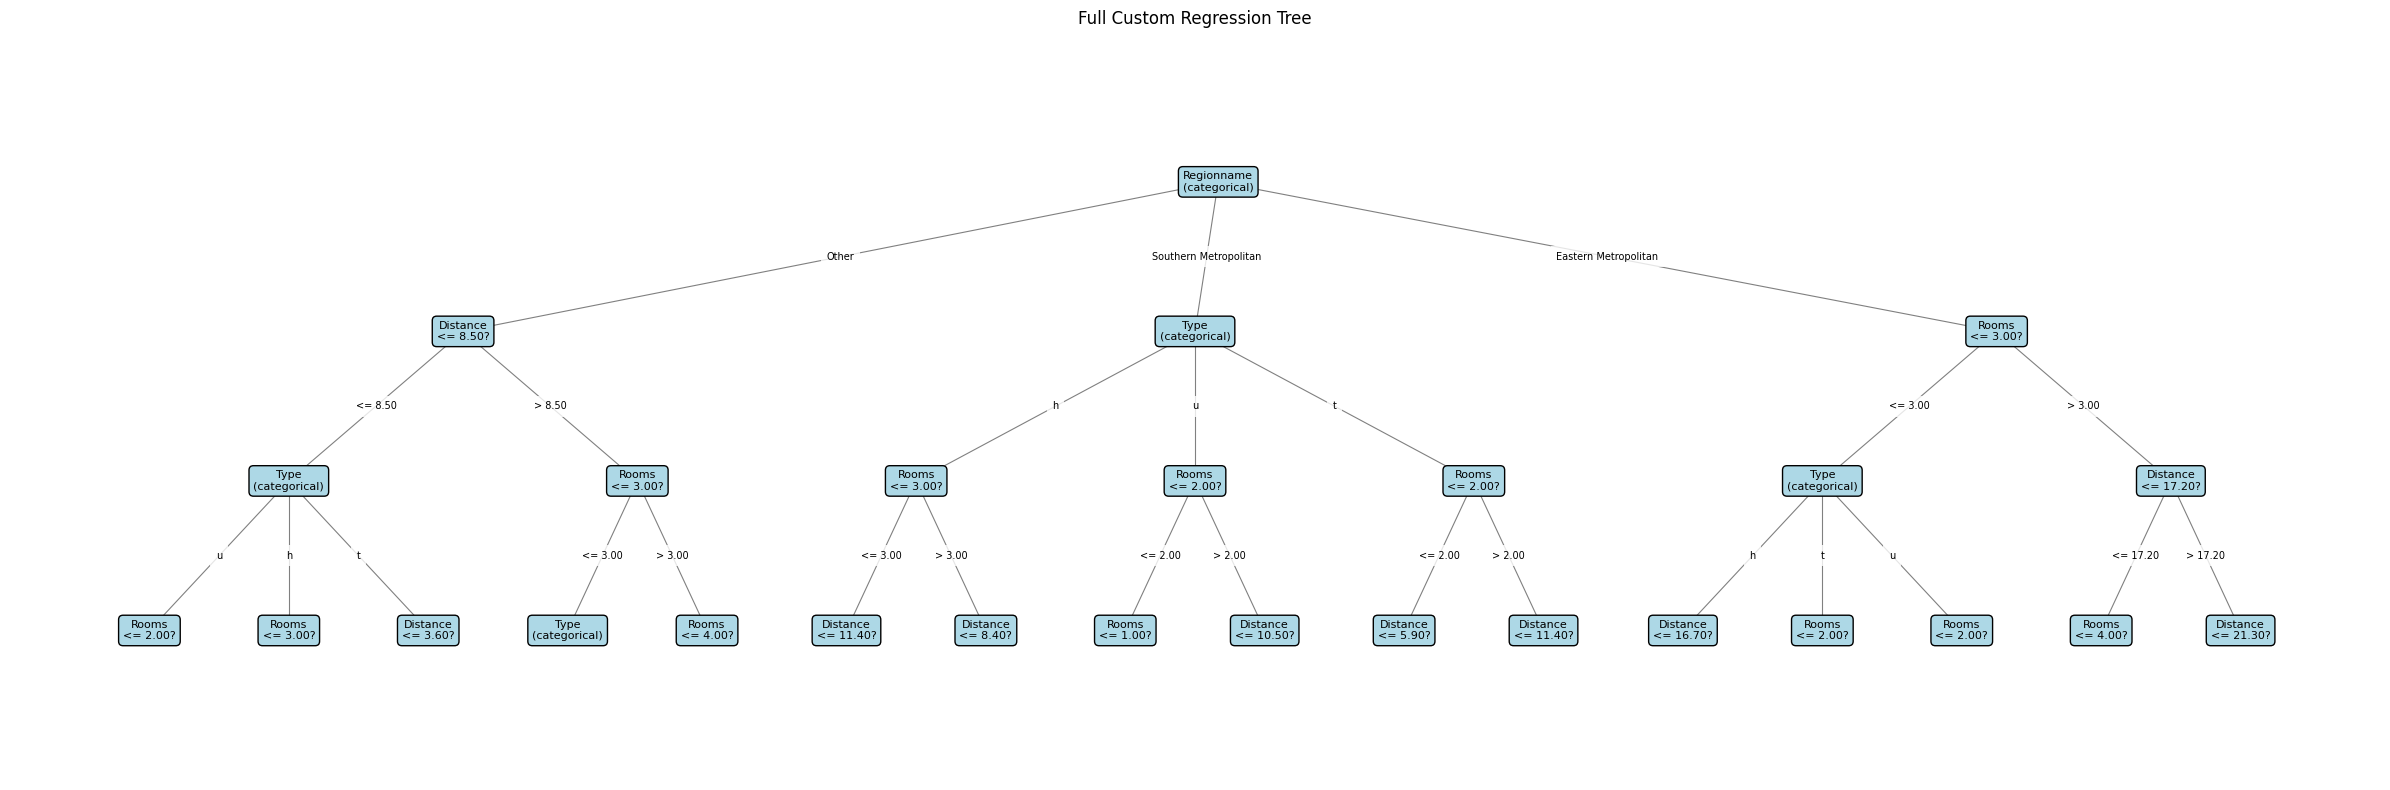

In [67]:
custom_trees[3].plot_my_tree(max_depth=3)

In [66]:
from sklearn.tree import DecisionTreeRegressor

X_train_sk = X_train.copy()
X_validation_sk = X_validation.copy()

for col in categorical_cols:
    X_train_sk[col] = X_train_sk[col].astype("category").cat.codes
    X_validation_sk[col] = X_validation_sk[col].astype("category").cat.codes

library_performance = []
library_trees = []

for ind, comb in enumerate(params_combinations):
    max_depth, min_samples_split, num_thresholds = params_combinations[ind]["max_depth"], params_combinations[ind]["min_samples_split"], params_combinations[ind]["num_thresholds"]
    tree = DecisionTreeRegressor(max_depth=max_depth, min_samples_split=min_samples_split)
    tree.fit(X_train_sk, y_train)
    
    library_trees.append(tree)

    y_train_predictions = tree.predict(X_train_sk)
    train_performance = evaluate_metrics(y_train, y_train_predictions)

    y_validation_predictions = tree.predict(X_validation_sk)
    validation_performance = evaluate_metrics(y_validation, y_validation_predictions)

    library_performance.append(
        {
            "max_depth": comb["max_depth"],
            "min_samples_split": comb["min_samples_split"],
            "num_thresholds": comb["num_thresholds"],
            "Train_MAE": train_performance["MAE"],
            "Val_MAE": validation_performance["MAE"],
            "Train_MAPE": train_performance["MAPE (%)"],
            "Val_MAPE": validation_performance["MAPE (%)"],
            "Train_R2": train_performance["R2"],
            "Val_R2": validation_performance["R2"],
        }
    )

results_df = pd.DataFrame(library_performance)
print(results_df.to_string(index=False))

 max_depth  min_samples_split  num_thresholds     Train_MAE       Val_MAE  Train_MAPE  Val_MAPE  Train_R2   Val_R2
         3                  2               5 293067.866867 290108.411300   32.459798 32.587971  0.462606 0.481541
         5                  2               5 236167.982106 233808.842353   24.711133 24.743664  0.614225 0.627087
         8                 10              10 202763.999926 208353.235383   20.933692 21.616033  0.708866 0.683802
        12                 10              10 169274.813796 187238.717753   16.917345 18.692689  0.781726 0.714248
      1000                  2              20 124253.180715 195746.007221   11.769399 18.876299  0.848421 0.657663


Classification desicion tree